# KT-02 · Notebook 03 — Khởi tạo trọng số (PHẦN 3)

In [1]:
import sys, os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")            # import code trong src/
os.makedirs("../reports", exist_ok=True)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from nn_numpy import PRETTY
from nn_numpy import DeepNet
from nn_numpy import fit
from nn_numpy import load_image_data
Xtr, Xva, ytr, yva, ten_data = load_image_data()
INITS = ["zeros", "small", "xavier", "he"]
LAB = {"zeros": "zeros (W=0)", "small": "random nhỏ N(0, 0.01²)", "xavier": "Xavier", "he": "He"}
KT = [Xtr.shape[1]] + [64] * 6 + [10]        # 6 tầng ẩn × 64 neuron
print("Dữ liệu:", ten_data, "| kiến trúc:", KT)

da check xong
Dữ liệu: sklearn digits (8×8) — thay MNIST | kiến trúc: [64, 64, 64, 64, 64, 64, 64, 10]


## Bước 10 — So sánh 4 cách khởi tạo: zeros · random nhỏ · Xavier · He

Mạng 6 tầng ẩn, SGD `lr=0.05`, 40 epoch, 3 seed (zeros thì giống hệt nhau giữa các seed). Hai bộ activation: **tanh** (lý thuyết: Xavier) và **ReLU** (lý thuyết: He).

ln(10) = 2.303 = loss của mạng đoán đều 10 lớp (chưa học gì)


,activation,khởi tạo,loss epoch 1,loss epoch 40,val acc (%)
0,Tanh,zeros (W=0),2.303,2.302,10.2
1,Tanh,"random nhỏ N(0, 0.01²)",2.303,2.302,10.2
2,Tanh,Xavier,1.489,0.043,96.7
3,Tanh,He,0.872,0.018,97.3
4,ReLU,zeros (W=0),2.303,2.302,10.2
5,ReLU,"random nhỏ N(0, 0.01²)",2.303,2.302,10.2
6,ReLU,Xavier,2.277,0.029,96.2
7,ReLU,He,1.725,0.006,96.2


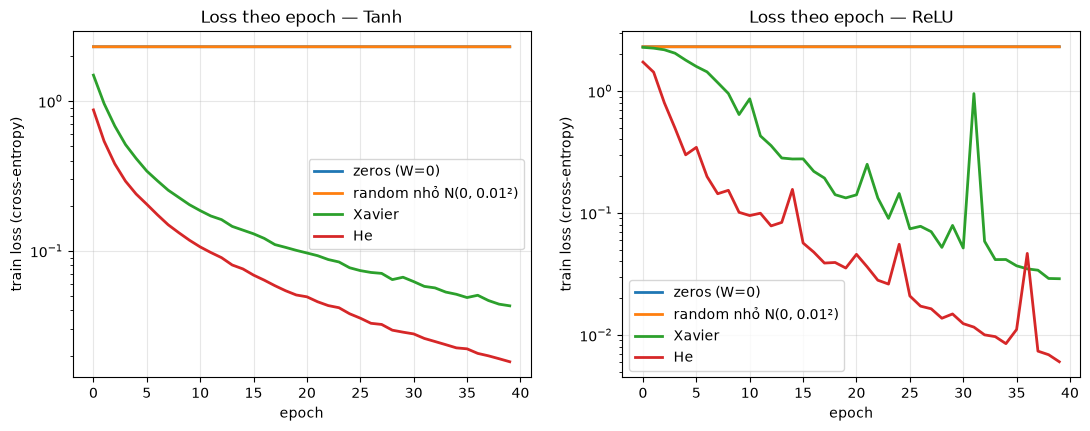

In [3]:
SEEDS, EPOCHS = [0, 1, 2], 40
res = {}
for act in ["tanh", "relu"]:
    for ini in INITS:
        res[(act, ini)] = [fit(DeepNet(KT, act=act, init=ini, seed=s), Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=0.05, seed=s) for s in SEEDS]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, act in zip(axs, ["tanh", "relu"]):
    for ini in INITS:
        ax.plot(np.mean([h["loss"] for h in res[(act, ini)]], 0), label=LAB[ini], lw=2)
    ax.set(title=f"Loss theo epoch — {PRETTY[act]}", xlabel="epoch", ylabel="train loss (cross-entropy)", yscale="log"); ax.legend()
plt.savefig("../reports/init_comparison.png", bbox_inches="tight")
rows = []
for (act, ini), hs in res.items():
    rows.append({"activation": PRETTY[act], "khởi tạo": LAB[ini], "loss epoch 1": f"{np.mean([h['loss'][0] for h in hs]):.3f}",
                 "loss epoch 40": f"{np.mean([h['loss'][-1] for h in hs]):.3f}", "val acc (%)": f"{np.mean([h['val_acc'][-1] for h in hs]) * 100:.1f}"})
tb = pd.DataFrame(rows)
print("ln(10) =", round(float(np.log(10)), 3), "= loss của mạng đoán đều 10 lớp (chưa học gì)")
tb

### Random nhỏ chỉ chậm hay kẹt hẳn? — train ReLU + random nhỏ lâu hơn (300 epoch)

In [4]:
net = DeepNet(KT, act="relu", init="small", seed=0)
h = fit(net, Xtr, ytr, Xva, yva, epochs=300, lr=0.05, seed=0)
print("loss tại epoch 1/40/100/200/300:", [round(h["loss"][i], 4) for i in [0, 39, 99, 199, 299]], "| val acc cuối:", f"{h['val_acc'][-1]:.1%}")

loss tại epoch 1/40/100/200/300: [2.3026, 2.3025, 2.3025, 2.3025, 2.3025] | val acc cuối: 10.2%


## Bước 11 — Khởi tạo zeros (và "mọi neuron cùng giá trị") ⇒ các neuron GIỐNG HỆT nhau mãi mãi

Hai thí nghiệm với mạng tanh 64→32→32→10, train 20 epoch:
- `zeros`: mọi trọng số = 0.
- `const`: mọi trọng số = 0.1 (**khác 0 nhưng giống nhau**) — đây mới là trường hợp "đối xứng" thuần tuý.
- `he`: đối chứng.

`spread` = chênh lệch lớn nhất giữa trọng số của các neuron trong cùng một tầng (0 nghĩa là giống hệt nhau).

In [5]:
for ini in ["zeros", "const", "he"]:
    net = DeepNet([Xtr.shape[1], 32, 32, 10], act="tanh", init=ini, seed=0)
    h = fit(net, Xtr, ytr, Xva, yva, epochs=20, lr=0.1, seed=0)
    W0 = net.p["W0"]
    print(f"=== init = {ini}  | loss sau 20 epoch = {h['loss'][-1]:.3f} | val acc = {h['val_acc'][-1]:.1%}")
    print("Trọng số vào (6 giá trị đầu) của 5 neuron đầu tiên ở tầng ẩn 1:")
    for j in range(5):
        print(f"  neuron {j}: {W0[:6, j].round(5)}")
    sp = [np.abs(net.p[f"W{i}"] - net.p[f"W{i}"][:, [0]]).max() for i in range(net.L - 1)]
    print("  spread giữa các neuron (tầng ẩn 1, 2):", [f"{v:.1e}" for v in sp], "| max|W0| =", f"{np.abs(W0).max():.3f}")
    print()

=== init = zeros  | loss sau 20 epoch = 2.302 | val acc = 10.2%
Trọng số vào (6 giá trị đầu) của 5 neuron đầu tiên ở tầng ẩn 1:
  neuron 0: [0. 0. 0. 0. 0. 0.]
  neuron 1: [0. 0. 0. 0. 0. 0.]
  neuron 2: [0. 0. 0. 0. 0. 0.]
  neuron 3: [0. 0. 0. 0. 0. 0.]
  neuron 4: [0. 0. 0. 0. 0. 0.]
  spread giữa các neuron (tầng ẩn 1, 2): ['0.0e+00', '0.0e+00'] | max|W0| = 0.000

=== init = const  | loss sau 20 epoch = 2.314 | val acc = 10.0%
Trọng số vào (6 giá trị đầu) của 5 neuron đầu tiên ở tầng ẩn 1:
  neuron 0: [0.1     0.1     0.09997 0.09994 0.09994 0.09997]
  neuron 1: [0.1     0.1     0.09997 0.09994 0.09994 0.09997]
  neuron 2: [0.1     0.1     0.09997 0.09994 0.09994 0.09997]
  neuron 3: [0.1     0.1     0.09997 0.09994 0.09994 0.09997]
  neuron 4: [0.1     0.1     0.09997 0.09994 0.09994 0.09997]
  spread giữa các neuron (tầng ẩn 1, 2): ['0.0e+00', '0.0e+00'] | max|W0| = 0.100

=== init = he  | loss sau 20 epoch = 0.127 | val acc = 96.0%
Trọng số vào (6 giá trị đầu) của 5 neuron đầu t

## Bước 12 — Phân phối activation qua từng tầng theo cách khởi tạo

Mạng **tanh 10 tầng × 256 neuron**, một batch 500 ảnh (đã chuẩn hoá), chỉ forward (chưa train).
Khởi tạo tốt giữ phân phối activation ổn định qua các tầng; khởi tạo tệ làm nó co về 0 hoặc bão hoà ở ±1.

,activation,khởi tạo,std tầng 1,std tầng 10
0,Tanh,zeros (W=0),0.00e+00,0.00e+00
1,Tanh,"random nhỏ N(0, 0.01²)",7.54e-02,4.91e-09
2,Tanh,Xavier,4.47e-01,2.05e-01
3,Tanh,He,6.80e-01,5.55e-01
4,ReLU,zeros (W=0),0.00e+00,0.00e+00
5,ReLU,"random nhỏ N(0, 0.01²)",4.55e-02,1.57e-10
6,ReLU,Xavier,3.60e-01,1.81e-02
7,ReLU,He,8.05e-01,9.16e-01


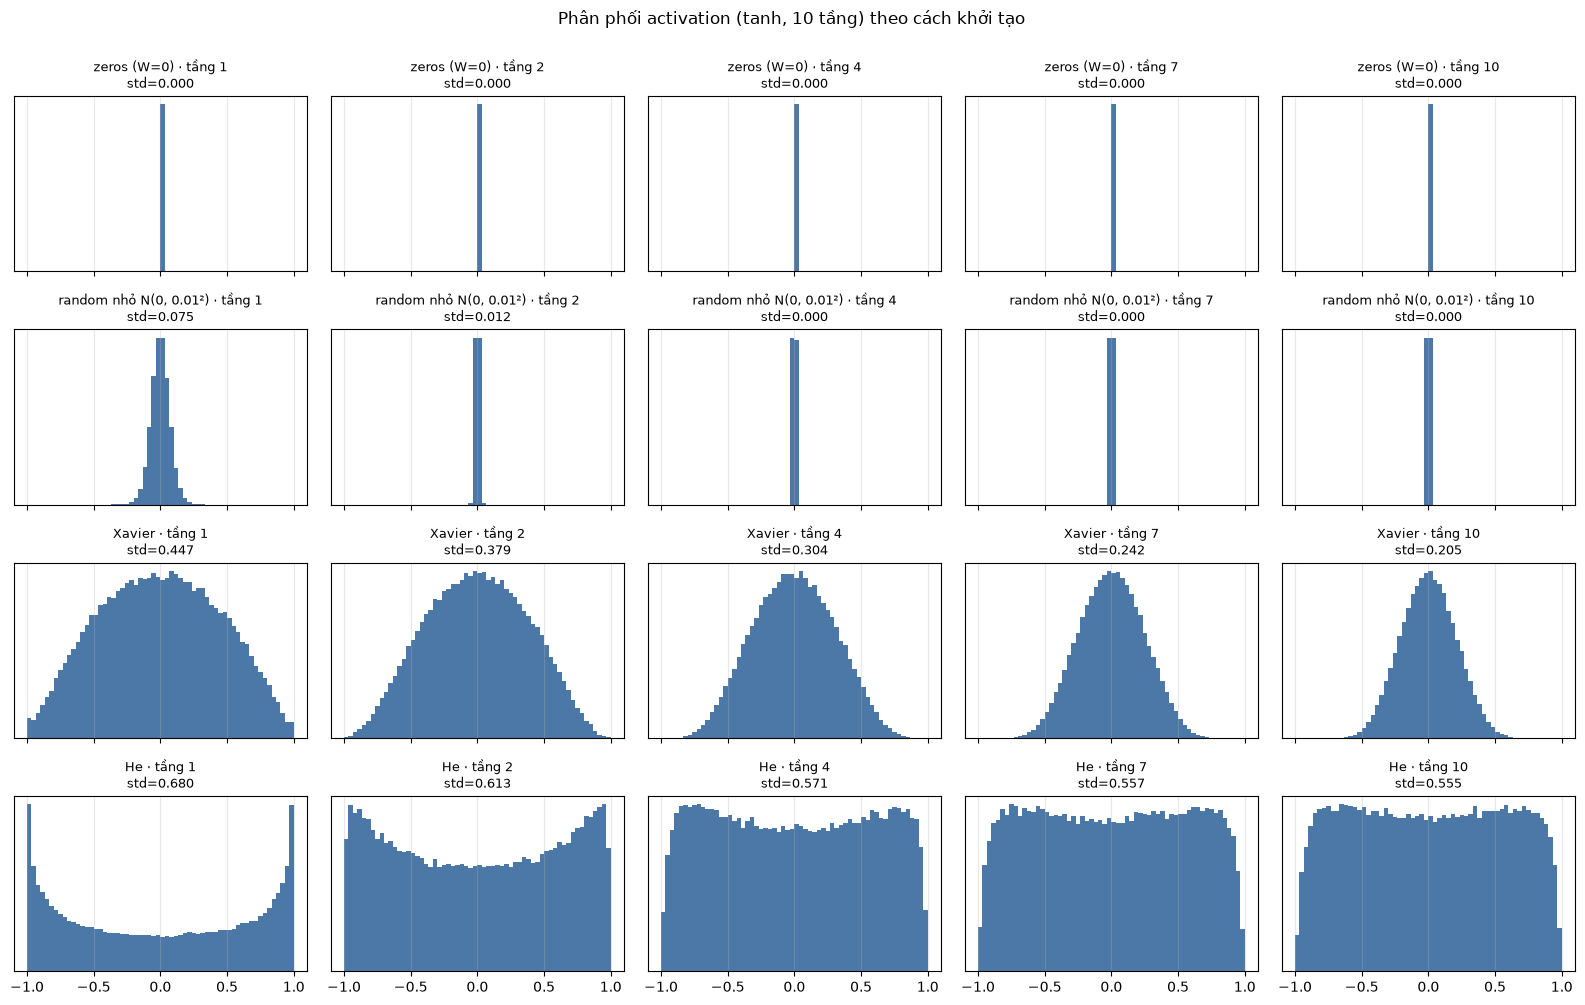

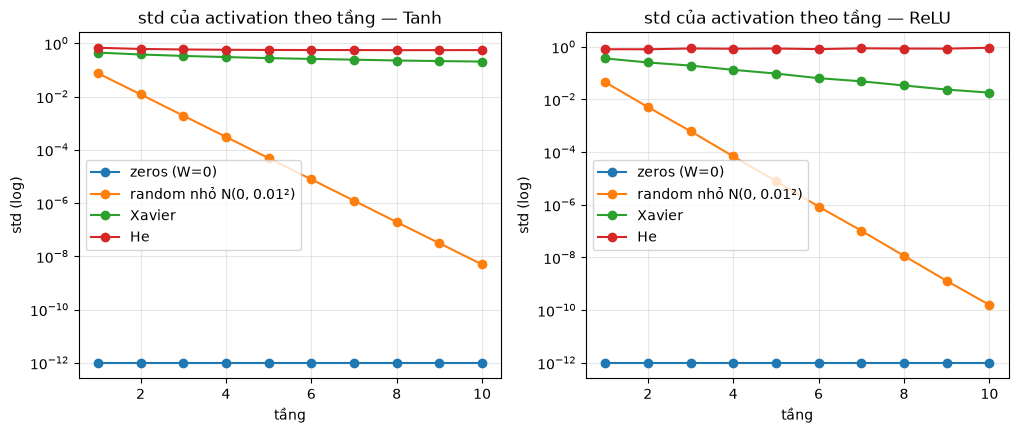

In [6]:
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8
Xb = ((Xtr - mu) / sd)[:500]
LAYERS = [1, 2, 4, 7, 10]
fig, axs = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
std_tbl = {}
for r, ini in enumerate(INITS):
    net = DeepNet([Xtr.shape[1]] + [256] * 10 + [10], act="tanh", init=ini, seed=0)
    net.forward(Xb, None, train=False)
    acts = [c["a"] for c in net.cache]
    std_tbl[ini] = [a.std() for a in acts]
    for c, L in enumerate(LAYERS):
        ax = axs[r, c]; a = acts[L - 1].ravel()
        ax.hist(a, bins=60, range=(-1, 1), color="#4c78a8")
        ax.set_title(f"{LAB[ini]} · tầng {L}\nstd={a.std():.3f}", fontsize=9); ax.set_yticks([])
plt.suptitle("Phân phối activation (tanh, 10 tầng) theo cách khởi tạo", y=1.0)
plt.tight_layout()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
rows = []
for ax, act in zip(axs, ["tanh", "relu"]):
    for ini in INITS:
        net = DeepNet([Xtr.shape[1]] + [256] * 10 + [10], act=act, init=ini, seed=0)
        net.forward(Xb, None, train=False)
        s = [c["a"].std() for c in net.cache]
        ax.semilogy(range(1, 11), np.maximum(s, 1e-12), "o-", label=LAB[ini])
        rows.append((PRETTY[act], LAB[ini], f"{s[0]:.2e}", f"{s[-1]:.2e}"))
    ax.set(title=f"std của activation theo tầng — {PRETTY[act]}", xlabel="tầng", ylabel="std (log)"); ax.legend()

pd.DataFrame(rows, columns=["activation", "khởi tạo", "std tầng 1", "std tầng 10"])

## Bước 13 — Thêm BatchNorm: mạng có bớt nhạy với khởi tạo không?

Cùng mạng ReLU 6 tầng ẩn như bước 10, thêm BatchNorm sau mỗi Linear (tự cài trong `deepnet.py`, đã kiểm chứng gradient). 3 seed.

Độ chênh val acc giữa 3 cách khởi tạo có ngẫu nhiên: không BN = 86.0 điểm | có BN = 0.7 điểm


,khởi tạo,val acc không BN (%),loss không BN,val acc BN (%),loss BN
0,zeros (W=0),10.222,2.302,10.222,2.302
1,"random nhỏ N(0, 0.01²)",10.222,2.302,97.556,0.004
2,Xavier,96.222,0.029,97.704,0.003
3,He,96.222,0.006,97.037,0.004


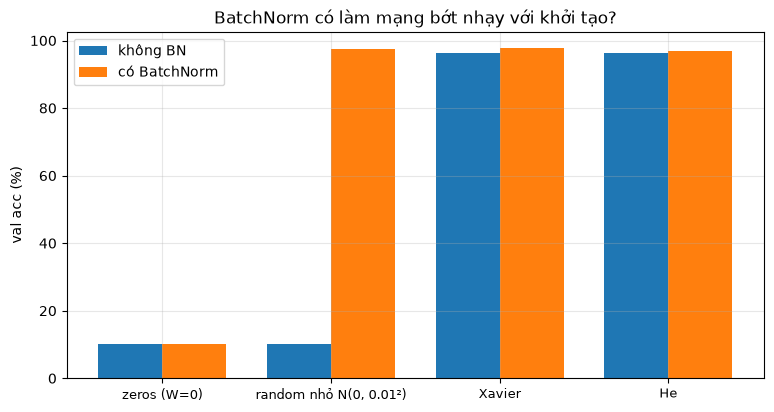

In [7]:
rows = []
for ini in INITS:
    r = {"khởi tạo": LAB[ini]}
    for bn in (False, True):
        hs = [fit(DeepNet(KT, act="relu", init=ini, batchnorm=bn, seed=s), Xtr, ytr, Xva, yva, epochs=40, lr=0.05, seed=s) for s in SEEDS]
        tag = "BN" if bn else "không BN"
        r[f"val acc {tag} (%)"] = np.mean([h["val_acc"][-1] for h in hs]) * 100
        r[f"loss {tag}"] = np.mean([h["loss"][-1] for h in hs])
    rows.append(r)
bn_tbl = pd.DataFrame(rows)
x = np.arange(len(INITS)); w = .38
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w / 2, bn_tbl["val acc không BN (%)"], w, label="không BN"); ax.bar(x + w / 2, bn_tbl["val acc BN (%)"], w, label="có BatchNorm")
ax.set_xticks(x); ax.set_xticklabels([LAB[i] for i in INITS], fontsize=9); ax.set(ylabel="val acc (%)", title="BatchNorm có làm mạng bớt nhạy với khởi tạo?"); ax.legend()

nz = ["small", "xavier", "he"]
sel = bn_tbl[bn_tbl["khởi tạo"].isin([LAB[i] for i in nz])]
print(f"Độ chênh val acc giữa 3 cách khởi tạo có ngẫu nhiên: không BN = {np.ptp(sel['val acc không BN (%)']):.1f} điểm | có BN = {np.ptp(sel['val acc BN (%)']):.1f} điểm")
bn_tbl.round(3)